# Vibe Coding Demo — Plant Growth

You're investigating whether **fertilizer** affects plant **height**, accounting for **light exposure**.

The data is in `data/plant_growth.csv`. **Don't open it and squint — ask your AI to brief you.**

Work the six steps below by *prompting*, not typing code. After each AI answer, ask yourself: **how would I know if this is wrong?**

## Step 1 — Orient by asking, not reading
**Prompt:** *"Load `data/plant_growth.csv`, summarize the columns, and tell me about data-quality problems I should worry about before analyzing it."*

👉 Read the answer skeptically. What did it find? What might it have **missed**?

In [1]:
# Let the AI fill this in from your prompt.


## Step 2 — Catch what it missed (the unit bug)
Some `height_cm` values are ~10x too large — a few rows were recorded in **millimetres**, not centimetres. The AI often flags these as "outliers" rather than a unit error. *You* know plants don't grow to 2 metres in this experiment.

**Prompt:** *"Some height values look like they're in millimetres (10x too large). Detect those rows, convert them to cm, and show me exactly which rows you changed and why."*

In [2]:
# --- Step 2: fix the millimetre rows -----------------------------------------
# A handful of height_cm values are ~10x too large: real heights sit around
# 12-30 cm, so anything > 60 cm can't be a plant in this experiment -- it was
# recorded in millimetres. We convert those rows to cm and show exactly what
# changed, so the fix is auditable rather than silent.
import numpy as np, pandas as pd

df = pd.read_csv("data/plant_growth.csv")

MM_THRESHOLD = 60                       # cm; no real plant here exceeds this
is_mm = df["height_cm"] > MM_THRESHOLD

changed = df.loc[is_mm, ["plant_id", "treatment", "height_cm"]].copy()
changed["height_cm_fixed"] = changed["height_cm"] / 10

df.loc[is_mm, "height_cm"] = df.loc[is_mm, "height_cm"] / 10

print(f"Rows converted from mm to cm: {is_mm.sum()}")
print(changed.to_string(index=False))
print(f"\nheight_cm range after fix: {df['height_cm'].min():.1f} - {df['height_cm'].max():.1f} cm")


Rows converted from mm to cm: 5
plant_id  treatment  height_cm  height_cm_fixed
    P001    control      209.0            20.90
    P043    control      219.4            21.94
    P049    control      185.0            18.50
    P052 fertilizer      205.0            20.50
    P065    control      157.0            15.70

height_cm range after fix: 12.6 - 29.9 cm


## Step 3 — Clean the rest
**Prompt:** *"Handle the missing values and the single implausible outlier. Tell me your strategy for each and why, before applying it."*

👉 Don't accept "I dropped the rows" silently — ask what that does to the analysis.

In [3]:
# --- Step 3: casing, missing values, and a residual-outlier check ------------
# Runs after Step 2 (df already has the mm rows fixed).

# 1) Normalise the treatment labels: 'Fertilizer' vs 'fertilizer' are the same
#    group. Left uncleaned this silently splits fertilizer into two levels.
before = df["treatment"].value_counts().to_dict()
df["treatment"] = df["treatment"].str.strip().str.lower()
print("treatment labels:", before, "->", df["treatment"].value_counts().to_dict())

# 2) Missing values. Strategy: DROP rows missing light_hours or height_cm.
#    Reasoning: both are core to the light-vs-height analysis, imputing the
#    response (height) would fabricate the very thing we're testing, and the
#    loss is modest. BUT the loss is not evenly spread across groups -- check
#    before trusting the comparison.
miss = df[["light_hours", "height_cm"]].isna().any(axis=1)
print(f"\nRows with missing light/height: {miss.sum()} of {len(df)}")
print("  by treatment:", df.loc[miss, "treatment"].value_counts().to_dict(),
      "  <- imbalanced: more missing in control, a bias to keep in mind")

df = df.dropna(subset=["light_hours", "height_cm"]).reset_index(drop=True)
print(f"Rows remaining after drop: {len(df)}")

# 3) Residual outlier check. The Step-3 framing expects "one implausible
#    outlier" -- verify rather than assume. With units fixed, is anything still
#    outside a 1.5*IQR fence?
for col in ["height_cm", "light_hours"]:
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = df[(df[col] < lo) | (df[col] > hi)]
    print(f"{col}: {len(out)} outliers beyond [{lo:.1f}, {hi:.1f}]")

print("\n=> No implausible outlier survives the unit fix; nothing further to drop.")
print(df.groupby("treatment")["height_cm"].describe()[["count", "mean", "std", "min", "max"]])


treatment labels: {'control': 60, 'fertilizer': 48, 'Fertilizer': 12} -> {'control': 60, 'fertilizer': 60}

Rows with missing light/height: 12 of 120
  by treatment: {'control': 9, 'fertilizer': 3}   <- imbalanced: more missing in control, a bias to keep in mind
Rows remaining after drop: 108
height_cm: 0 outliers beyond [8.7, 34.8]
light_hours: 0 outliers beyond [0.5, 17.0]

=> No implausible outlier survives the unit fix; nothing further to drop.
            count       mean       std   min   max
treatment                                         
control      51.0  18.381176  2.667296  12.6  25.4
fertilizer   57.0  24.707018  2.766887  18.2  29.9


## Step 4 — Diverge: three ways to test the effect
**Prompt:** *"Give me three ways to test whether fertilizer affects height, controlling for light hours, and the assumptions each one makes."*

👉 Pick one **deliberately**. Note: the treatment labels have a casing inconsistency (`fertilizer` vs `Fertilizer`) — does your chosen method handle it?

## Step 5 — Visualize
**Prompt:** *"Make a clear plot that shows the fertilizer effect while accounting for light hours."*

👉 Does the picture match the statistic? If they disagree, one of them is wrong.

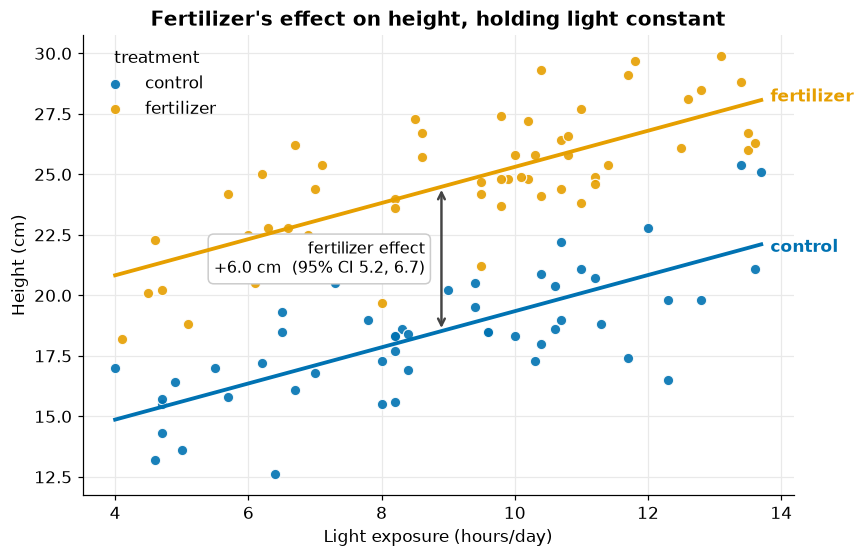

adjusted fertilizer effect: +5.96 cm  (95% CI 5.24, 6.69),  p=1.28e-30
shared light slope:         +0.75 cm/hour


In [4]:
# --- Step 5: visualize the fertilizer effect, accounting for light hours ---
# Reproduces the cleaning from Steps 2-3 so this cell runs standalone.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

df = pd.read_csv("data/plant_growth.csv")
df["treatment"] = df["treatment"].str.strip().str.lower()          # fix 'Fertilizer' casing
mm = df["height_cm"] > 60                                           # ~10x too big => mm recorded as cm
df.loc[mm, "height_cm"] = df.loc[mm, "height_cm"] / 10              # unit fix (Step 2)
df = df.dropna(subset=["light_hours", "height_cm"]).reset_index(drop=True)  # drop missing (Step 3)

# ANCOVA / parallel-slopes: height ~ light + treatment. The coefficient on
# fertilizer is the effect *holding light constant* -> the vertical gap between
# the two lines. NB: read params by NAME, not position (statsmodels orders them
# Intercept, treatment, light_hours -- easy to swap by accident).
m = smf.ols("height_cm ~ light_hours + C(treatment, Treatment('control'))", data=df).fit()
fert_term = [c for c in m.params.index if "fertilizer" in c][0]
eff    = m.params[fert_term]
lo, hi = m.conf_int().loc[fert_term]
b0, b1 = m.params["Intercept"], m.params["light_hours"]

CTRL, FERT = "#0072B2", "#E69F00"              # CVD-safe categorical pair (validated)
colors = {"control": CTRL, "fertilizer": FERT}

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
fig, ax = plt.subplots(figsize=(8, 5.2))

for t, g in df.groupby("treatment"):
    ax.scatter(g["light_hours"], g["height_cm"], s=46, c=colors[t],
               edgecolor="white", linewidth=0.8, alpha=0.9, zorder=3, label=t)

xs = np.linspace(df["light_hours"].min(), df["light_hours"].max(), 100)
ax.plot(xs, b0 + b1*xs,       color=CTRL, lw=2.5, zorder=4)         # control line
ax.plot(xs, b0 + eff + b1*xs, color=FERT, lw=2.5, zorder=4)         # fertilizer line (parallel)

# direct labels -> identity is never carried by color alone
xr = xs[-1]
ax.annotate("control",    (xr, b0 + b1*xr),       color=CTRL, fontweight="bold",
            xytext=(6, -2), textcoords="offset points", va="center")
ax.annotate("fertilizer", (xr, b0 + eff + b1*xr), color=FERT, fontweight="bold",
            xytext=(6, 2),  textcoords="offset points", va="center")

# the gap = adjusted fertilizer effect
xm = xs[len(xs)//2]
yc, yf = b0 + b1*xm, b0 + eff + b1*xm
ax.annotate("", (xm, yf), (xm, yc), arrowprops=dict(arrowstyle="<->", color="#444", lw=1.6))
ax.text(xm - 0.25, (yc+yf)/2,
        f"fertilizer effect\n{eff:+.1f} cm  (95% CI {lo:.1f}, {hi:.1f})",
        ha="right", va="center", fontsize=10.5,
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#ccc"))

ax.set_xlabel("Light exposure (hours/day)")
ax.set_ylabel("Height (cm)")
ax.set_title("Fertilizer's effect on height, holding light constant", fontweight="bold")
ax.grid(True, color="#e9e9e9", lw=0.8, zorder=0)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(title="treatment", frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

print(f"adjusted fertilizer effect: {eff:+.2f} cm  (95% CI {lo:.2f}, {hi:.2f}),  p={m.pvalues[fert_term]:.3g}")
print(f"shared light slope:         {b1:+.2f} cm/hour")


## Step 6 — Slow down at the claim
**Prompt:** *"State the conclusion in one sentence with the effect size and uncertainty. Then tell me what would make this conclusion wrong and what assumptions you made."*

👉 This verification prompt is **part of the workflow**, not an afterthought.

### Bonus — harden it
**Prompt:** *"Turn this notebook into a single script I can rerun from scratch to reproduce the result."*